In [1]:
import sqlite3
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import mutual_info_regression

from sklearn.preprocessing import OrdinalEncoder

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBClassifier
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")

db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"

conn = sqlite3.connect(db_path)

print("Connected successfully")

Connected successfully


In [2]:
crop_fe = pd.read_sql_query(
    "SELECT * FROM crop_recommendation_fe",
    conn
)

train_fe = pd.read_sql_query(
    "SELECT * FROM agri_yield_train_fe",
    conn
)

test_fe = pd.read_sql_query(
    "SELECT * FROM agri_yield_test_fe",
    conn
)

print("Crop Recommendation:", crop_fe.shape)
print("Yield Train:", train_fe.shape)
print("Yield Test:", test_fe.shape)

Crop Recommendation: (2200, 33)
Yield Train: (10000, 15)
Yield Test: (2000, 14)


In [3]:
X_crop = crop_fe.drop(columns=["label"])
y_crop = crop_fe["label"]

print("Crop X shape:", X_crop.shape)
print("Crop y shape:", y_crop.shape)

Crop X shape: (2200, 32)
Crop y shape: (2200,)


In [4]:
X_yield = train_fe.drop(
    columns=["yield", "field_id"]
)

y_yield = train_fe["yield"]

X_yield_test = test_fe.drop(
    columns=["field_id"]
)

print("Yield X shape:", X_yield.shape)
print("Yield y shape:", y_yield.shape)
print("Yield Test X shape:", X_yield_test.shape)

Yield X shape: (10000, 13)
Yield y shape: (10000,)
Yield Test X shape: (2000, 13)


In [5]:
crop_numeric = X_crop.select_dtypes(
    include=np.number
).columns.tolist()

crop_categorical = X_crop.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Crop Numerical Features:")
print(crop_numeric)

print("\nCrop Categorical Features:")
print(crop_categorical)

Crop Numerical Features:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'soil_moisture', 'soil_type', 'sunlight_exposure', 'wind_speed', 'co2_concentration', 'organic_matter', 'irrigation_frequency', 'crop_density', 'pest_pressure', 'fertilizer_usage', 'growth_stage', 'urban_area_proximity', 'water_source_type', 'frost_risk', 'water_usage_efficiency', 'NPK_Total', 'N_P_Ratio', 'N_K_Ratio', 'P_K_Ratio', 'Temperature_Humidity', 'Temperature_Rainfall', 'Humidity_Rainfall', 'Moisture_Rainfall_Ratio', 'Irrigation_Water_Efficiency', 'Density_Pest_Interaction']

Crop Categorical Features:
[]


In [6]:
yield_numeric = X_yield.select_dtypes(
    include=np.number
).columns.tolist()

yield_categorical = X_yield.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Yield Numerical Features:")
print(yield_numeric)

print("\nYield Categorical Features:")
print(yield_categorical)

Yield Numerical Features:
['soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi', 'Temperature_Humidity', 'Temperature_Rainfall', 'Humidity_Rainfall', 'NDVI_Rainfall', 'NDVI_Temperature', 'OrganicMatter_Sand']

Yield Categorical Features:
[]


In [7]:
crop_constant = [
    col for col in X_crop.columns
    if X_crop[col].nunique() <= 1
]

yield_constant = [
    col for col in X_yield.columns
    if X_yield[col].nunique() <= 1
]

print("Crop constant features:")
print(crop_constant)

print("\nYield constant features:")
print(yield_constant)

Crop constant features:
[]

Yield constant features:
[]


In [8]:
if crop_constant:
    X_crop = X_crop.drop(
        columns=crop_constant
    )

if yield_constant:
    X_yield = X_yield.drop(
        columns=yield_constant
    )

print("Crop shape after constant removal:", X_crop.shape)
print("Yield shape after constant removal:", X_yield.shape)

Crop shape after constant removal: (2200, 32)
Yield shape after constant removal: (10000, 13)


In [9]:
print("Crop missing values:")
display(X_crop.isnull().sum())

print("\nYield missing values:")
display(X_yield.isnull().sum())

Crop missing values:


N                              0
P                              0
K                              0
temperature                    0
humidity                       0
ph                             0
rainfall                       0
soil_moisture                  0
soil_type                      0
sunlight_exposure              0
wind_speed                     0
co2_concentration              0
organic_matter                 0
irrigation_frequency           0
crop_density                   0
pest_pressure                  0
fertilizer_usage               0
growth_stage                   0
urban_area_proximity           0
water_source_type              0
frost_risk                     0
water_usage_efficiency         0
NPK_Total                      0
N_P_Ratio                      0
N_K_Ratio                      0
P_K_Ratio                      0
Temperature_Humidity           0
Temperature_Rainfall           0
Humidity_Rainfall              0
Moisture_Rainfall_Ratio        0
Irrigation


Yield missing values:


soil_ph                 0
organic_matter          0
sand_pct                0
temperature             0
humidity                0
rainfall                0
ndvi                    0
Temperature_Humidity    0
Temperature_Rainfall    0
Humidity_Rainfall       0
NDVI_Rainfall           0
NDVI_Temperature        0
OrganicMatter_Sand      0
dtype: int64

In [10]:
print("Crop missing values:")
display(X_crop.isnull().sum())

print("\nYield missing values:")
display(X_yield.isnull().sum())

Crop missing values:


N                              0
P                              0
K                              0
temperature                    0
humidity                       0
ph                             0
rainfall                       0
soil_moisture                  0
soil_type                      0
sunlight_exposure              0
wind_speed                     0
co2_concentration              0
organic_matter                 0
irrigation_frequency           0
crop_density                   0
pest_pressure                  0
fertilizer_usage               0
growth_stage                   0
urban_area_proximity           0
water_source_type              0
frost_risk                     0
water_usage_efficiency         0
NPK_Total                      0
N_P_Ratio                      0
N_K_Ratio                      0
P_K_Ratio                      0
Temperature_Humidity           0
Temperature_Rainfall           0
Humidity_Rainfall              0
Moisture_Rainfall_Ratio        0
Irrigation


Yield missing values:


soil_ph                 0
organic_matter          0
sand_pct                0
temperature             0
humidity                0
rainfall                0
ndvi                    0
Temperature_Humidity    0
Temperature_Rainfall    0
Humidity_Rainfall       0
NDVI_Rainfall           0
NDVI_Temperature        0
OrganicMatter_Sand      0
dtype: int64

In [13]:
yield_corr = (
    pd.concat(
        [X_yield_mi, y_yield],
        axis=1
    )
    .corr()["yield"]
    .drop("yield")
    .sort_values(
        key=abs,
        ascending=False
    )
)

display(yield_corr)

rainfall                0.016959
Humidity_Rainfall       0.015530
temperature            -0.014943
Temperature_Rainfall    0.010961
NDVI_Rainfall           0.008303
Temperature_Humidity   -0.008135
soil_ph                 0.007098
NDVI_Temperature       -0.006547
OrganicMatter_Sand     -0.004481
sand_pct               -0.003933
organic_matter          0.002207
ndvi                   -0.001619
humidity                0.001252
Name: yield, dtype: float64

In [12]:
# Prepare yield data for Mutual Information and Correlation

X_yield_mi = X_yield.copy()

for col in X_yield_mi.select_dtypes(include=np.number).columns:
    X_yield_mi[col] = X_yield_mi[col].fillna(
        X_yield_mi[col].median()
    )

print("X_yield_mi created successfully")
print(X_yield_mi.shape)
display(X_yield_mi.head())

X_yield_mi created successfully
(10000, 13)


,soil_ph,organic_matter,sand_pct,temperature,humidity,rainfall,ndvi,Temperature_Humidity,Temperature_Rainfall,Humidity_Rainfall,NDVI_Rainfall,NDVI_Temperature,OrganicMatter_Sand
0,6.25,2.66,41.6,25.2,70,110.2,0.46,1764.0,2777.04,7714.0,50.692,11.592,110.656
1,6.70,3.66,40.2,26.9,78,126.3,0.59,2098.2,3397.47,9851.4,74.517,15.871,147.132
2,7.21,3.45,40.0,27.6,66,109.4,0.64,1821.6,3019.44,7220.4,70.016,17.664,138.000
3,5.73,2.48,56.9,29.6,79,155.3,0.62,2338.4,4596.88,12268.7,96.286,18.352,141.112
4,6.88,3.61,30.6,25.0,80,172.6,0.62,2000.0,4315.00,13808.0,107.012,15.500,110.466


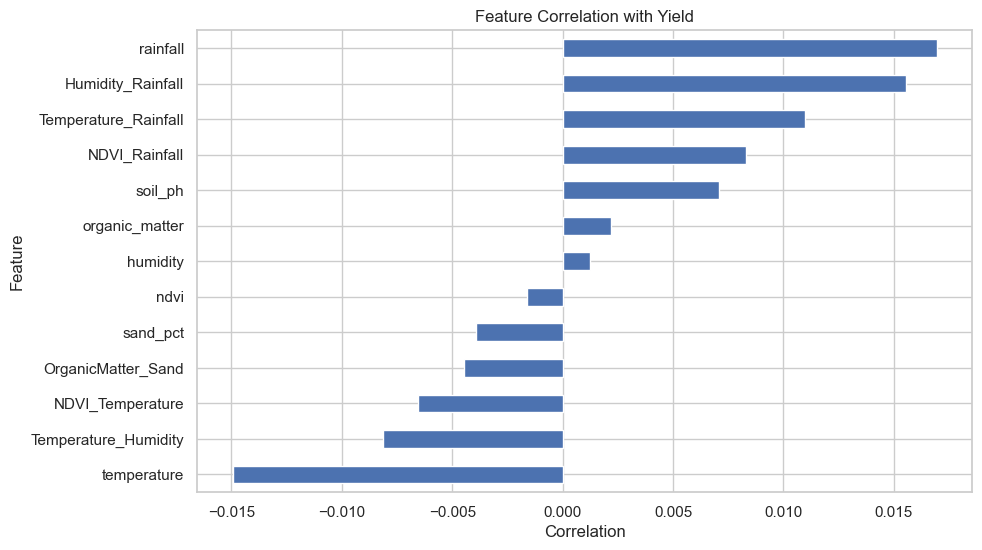

In [14]:
plt.figure(figsize=(10, 6))

yield_corr.sort_values().plot(
    kind="barh"
)

plt.title("Feature Correlation with Yield")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.show()

In [15]:
yield_corr_matrix = X_yield_mi.corr().abs()

upper = yield_corr_matrix.where(
    np.triu(
        np.ones(yield_corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = []

for column in upper.columns:
    for row in upper.index:
        
        value = upper.loc[row, column]
        
        if pd.notna(value) and value >= 0.90:
            high_corr_pairs.append(
                (row, column, value)
            )

high_corr_pairs

[('rainfall', 'Temperature_Rainfall', np.float64(0.9288715481427837)),
 ('rainfall', 'Humidity_Rainfall', np.float64(0.9023118470256312)),
 ('ndvi', 'NDVI_Temperature', np.float64(0.9360800145828041))]

In [16]:
mi_yield = mutual_info_regression(
    X_yield_mi,
    y_yield,
    random_state=42
)

mi_yield_df = pd.DataFrame({
    "feature": X_yield_mi.columns,
    "mutual_information": mi_yield
})

mi_yield_df = mi_yield_df.sort_values(
    "mutual_information",
    ascending=False
)

display(mi_yield_df)

,feature,mutual_information
5,rainfall,0.016942
8,Temperature_Rainfall,0.006763
7,Temperature_Humidity,0.003849
9,Humidity_Rainfall,0.002658
10,NDVI_Rainfall,0.002613
11,NDVI_Temperature,0.001852
0,soil_ph,0.000000
1,organic_matter,0.000000
2,sand_pct,0.000000
3,temperature,0.000000


<Figure size 1000x600 with 0 Axes>

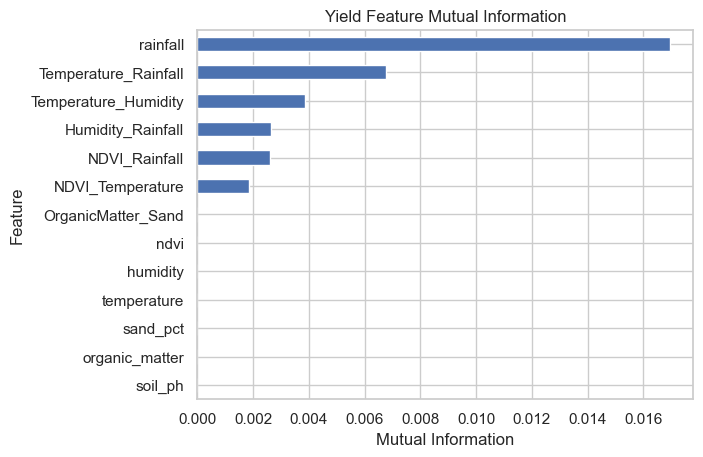

In [17]:
plt.figure(figsize=(10, 6))

mi_yield_df.sort_values(
    "mutual_information"
).plot(
    x="feature",
    y="mutual_information",
    kind="barh",
    legend=False
)

plt.title("Yield Feature Mutual Information")
plt.xlabel("Mutual Information")
plt.ylabel("Feature")

plt.show()

In [18]:
rf_yield = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_yield.fit(
    X_yield_mi,
    y_yield
)

,n_estimators,300
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [19]:
rf_yield_importance = pd.DataFrame({
    "feature": X_yield_mi.columns,
    "importance": rf_yield.feature_importances_
})

rf_yield_importance = rf_yield_importance.sort_values(
    "importance",
    ascending=False
)

display(rf_yield_importance)

,feature,importance
0,soil_ph,0.102533
12,OrganicMatter_Sand,0.092739
2,sand_pct,0.090763
1,organic_matter,0.087069
10,NDVI_Rainfall,0.084821
9,Humidity_Rainfall,0.084011
7,Temperature_Humidity,0.081976
11,NDVI_Temperature,0.080352
8,Temperature_Rainfall,0.080283
5,rainfall,0.073585


<Figure size 1000x600 with 0 Axes>

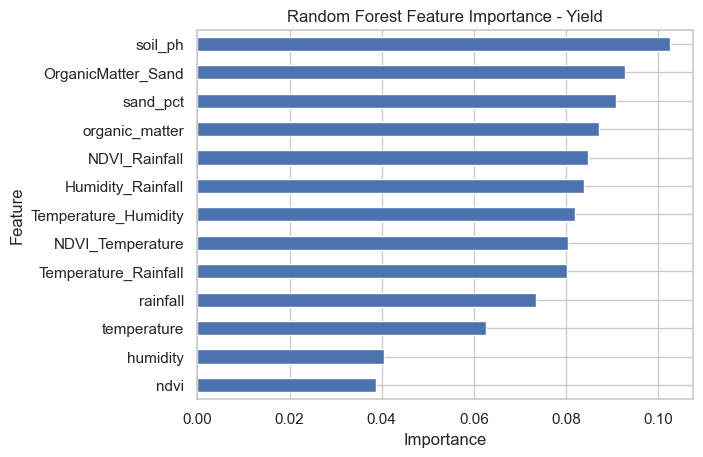

In [20]:
plt.figure(figsize=(10, 6))

rf_yield_importance.sort_values(
    "importance"
).plot(
    x="feature",
    y="importance",
    kind="barh",
    legend=False
)

plt.title("Random Forest Feature Importance - Yield")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [21]:
xgb_yield = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    random_state=42,
    objective="reg:squarederror"
)

xgb_yield.fit(
    X_yield_mi,
    y_yield
)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [22]:
xgb_yield_importance = pd.DataFrame({
    "feature": X_yield_mi.columns,
    "importance": xgb_yield.feature_importances_
})

xgb_yield_importance = xgb_yield_importance.sort_values(
    "importance",
    ascending=False
)

display(xgb_yield_importance)

,feature,importance
12,OrganicMatter_Sand,0.089719
10,NDVI_Rainfall,0.089010
8,Temperature_Rainfall,0.088335
7,Temperature_Humidity,0.086303
11,NDVI_Temperature,0.085663
9,Humidity_Rainfall,0.084193
5,rainfall,0.077164
3,temperature,0.071789
6,ndvi,0.070080
2,sand_pct,0.069304


<Figure size 1000x600 with 0 Axes>

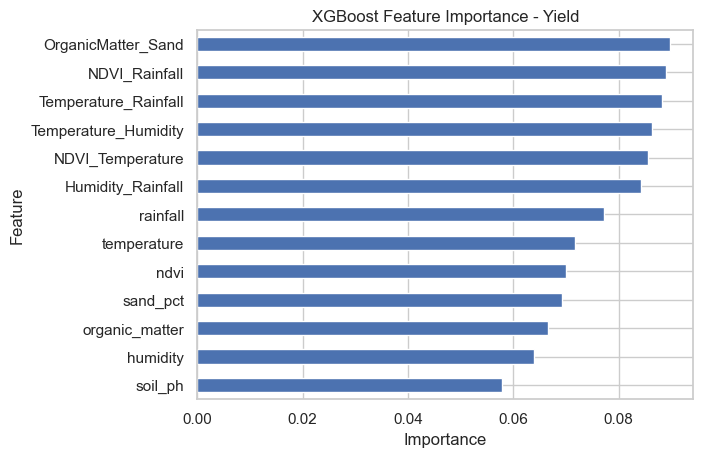

In [23]:
plt.figure(figsize=(10, 6))

xgb_yield_importance.sort_values(
    "importance"
).plot(
    x="feature",
    y="importance",
    kind="barh",
    legend=False
)

plt.title("XGBoost Feature Importance - Yield")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [24]:
print("Categorical features:")
print(crop_categorical)

Categorical features:
[]


In [25]:
X_crop_encoded = X_crop.copy()

crop_cat_current = X_crop_encoded.select_dtypes(
    exclude=np.number
).columns.tolist()

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

if crop_cat_current:
    X_crop_encoded[crop_cat_current] = encoder.fit_transform(
        X_crop_encoded[crop_cat_current]
    )

In [26]:
for col in X_crop_encoded.columns:
    
    if X_crop_encoded[col].isnull().any():
        
        if X_crop_encoded[col].dtype.kind in "biufc":
            X_crop_encoded[col] = X_crop_encoded[col].fillna(
                X_crop_encoded[col].median()
            )

In [27]:
print(
    "Crop missing values:",
    X_crop_encoded.isnull().sum().sum()
)

Crop missing values: 0


In [28]:
mi_crop = mutual_info_classif(
    X_crop_encoded,
    y_crop,
    random_state=42
)

mi_crop_df = pd.DataFrame({
    "feature": X_crop_encoded.columns,
    "mutual_information": mi_crop
})

mi_crop_df = mi_crop_df.sort_values(
    "mutual_information",
    ascending=False
)

display(mi_crop_df)

,feature,mutual_information
4,humidity,1.729954
28,Humidity_Rainfall,1.670117
2,K,1.658803
6,rainfall,1.637358
22,NPK_Total,1.391783
1,P,1.295148
25,P_K_Ratio,1.277405
26,Temperature_Humidity,1.242433
27,Temperature_Rainfall,1.216964
24,N_K_Ratio,1.078117


<Figure size 1000x800 with 0 Axes>

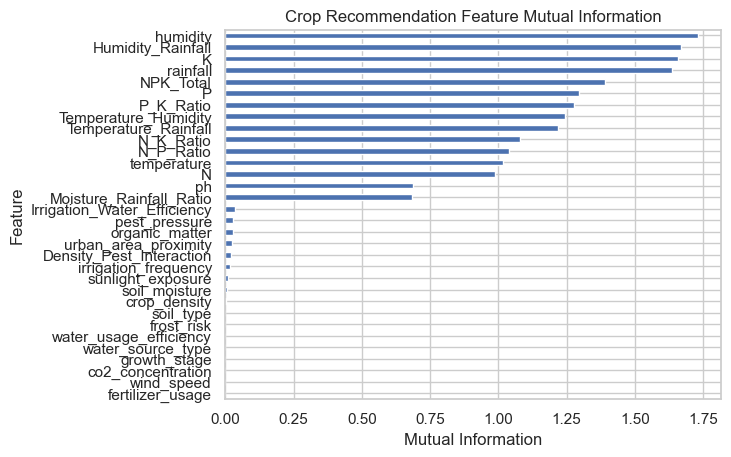

In [29]:
plt.figure(figsize=(10, 8))

mi_crop_df.sort_values(
    "mutual_information"
).plot(
    x="feature",
    y="mutual_information",
    kind="barh",
    legend=False
)

plt.title("Crop Recommendation Feature Mutual Information")
plt.xlabel("Mutual Information")
plt.ylabel("Feature")

plt.show()

In [30]:
rf_crop = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_crop.fit(
    X_crop_encoded,
    y_crop
)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [31]:
rf_crop_importance = pd.DataFrame({
    "feature": X_crop_encoded.columns,
    "importance": rf_crop.feature_importances_
})

rf_crop_importance = rf_crop_importance.sort_values(
    "importance",
    ascending=False
)

display(rf_crop_importance)

,feature,importance
4,humidity,0.117554
6,rainfall,0.103524
28,Humidity_Rainfall,0.098813
2,K,0.090875
22,NPK_Total,0.077610
1,P,0.076369
27,Temperature_Rainfall,0.071040
26,Temperature_Humidity,0.068654
25,P_K_Ratio,0.054890
0,N,0.052798


<Figure size 1000x800 with 0 Axes>

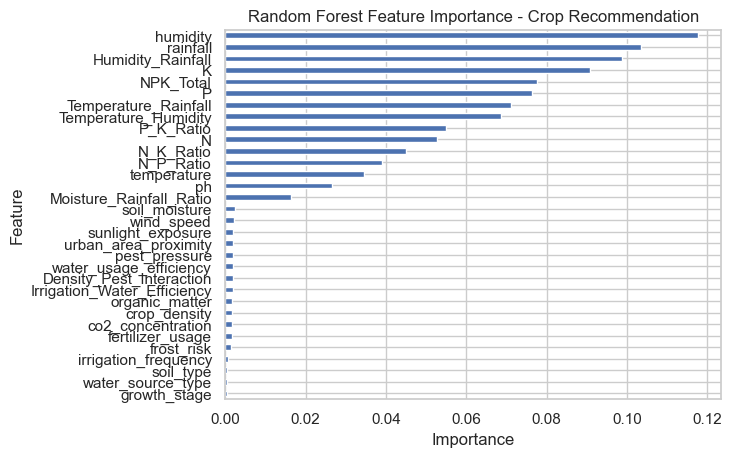

In [32]:
plt.figure(figsize=(10, 8))

rf_crop_importance.sort_values(
    "importance"
).plot(
    x="feature",
    y="importance",
    kind="barh",
    legend=False
)

plt.title("Random Forest Feature Importance - Crop Recommendation")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [33]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_crop_encoded = label_encoder.fit_transform(
    y_crop
)

print("Number of crop classes:", len(label_encoder.classes_))

Number of crop classes: 22


In [34]:
xgb_crop = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    random_state=42,
    objective="multi:softprob",
    eval_metric="mlogloss"
)

xgb_crop.fit(
    X_crop_encoded,
    y_crop_encoded
)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'mlogloss'


In [35]:
xgb_crop_importance = pd.DataFrame({
    "feature": X_crop_encoded.columns,
    "importance": xgb_crop.feature_importances_
})

xgb_crop_importance = xgb_crop_importance.sort_values(
    "importance",
    ascending=False
)

display(xgb_crop_importance)

,feature,importance
2,K,0.115991
24,N_K_Ratio,0.110360
6,rainfall,0.090104
1,P,0.083858
4,humidity,0.073469
0,N,0.070143
28,Humidity_Rainfall,0.066845
22,NPK_Total,0.061962
26,Temperature_Humidity,0.056122
3,temperature,0.054070


<Figure size 1000x800 with 0 Axes>

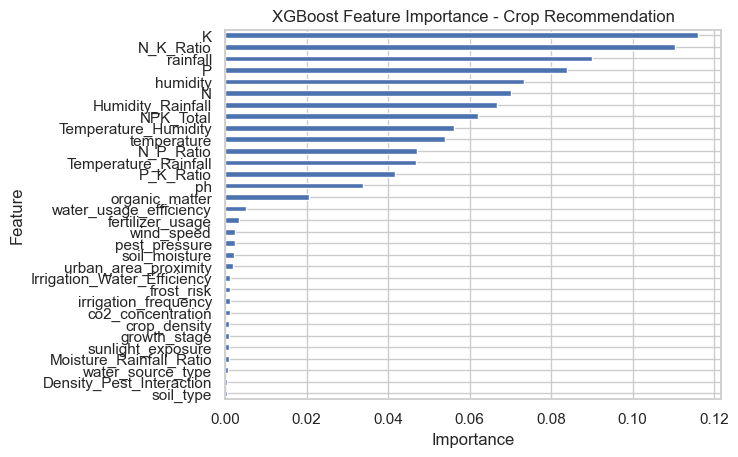

In [36]:
plt.figure(figsize=(10, 8))

xgb_crop_importance.sort_values(
    "importance"
).plot(
    x="feature",
    y="importance",
    kind="barh",
    legend=False
)

plt.title("XGBoost Feature Importance - Crop Recommendation")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [37]:
yield_selection = (
    rf_yield_importance
    .merge(
        xgb_yield_importance,
        on="feature",
        suffixes=(
            "_random_forest",
            "_xgboost"
        )
    )
    .merge(
        mi_yield_df,
        on="feature"
    )
)

yield_selection["abs_correlation"] = (
    yield_selection["feature"]
    .map(yield_corr.abs())
)

yield_selection = yield_selection.sort_values(
    "importance_xgboost",
    ascending=False
)

display(yield_selection)

,feature,importance_random_forest,importance_xgboost,mutual_information,abs_correlation
1,OrganicMatter_Sand,0.092739,0.089719,0.000000,0.004481
4,NDVI_Rainfall,0.084821,0.089010,0.002613,0.008303
8,Temperature_Rainfall,0.080283,0.088335,0.006763,0.010961
6,Temperature_Humidity,0.081976,0.086303,0.003849,0.008135
7,NDVI_Temperature,0.080352,0.085663,0.001852,0.006547
5,Humidity_Rainfall,0.084011,0.084193,0.002658,0.015530
9,rainfall,0.073585,0.077164,0.016942,0.016959
10,temperature,0.062576,0.071789,0.000000,0.014943
12,ndvi,0.038772,0.070080,0.000000,0.001619
2,sand_pct,0.090763,0.069304,0.000000,0.003933


In [38]:

crop_selection = (
    rf_crop_importance
    .merge(
        xgb_crop_importance,
        on="feature",
        suffixes=(
            "_random_forest",
            "_xgboost"
        )
    )
    .merge(
        mi_crop_df,
        on="feature"
    )
)

crop_selection = crop_selection.sort_values(
    "importance_xgboost",
    ascending=False
)

display(crop_selection)

,feature,importance_random_forest,importance_xgboost,mutual_information
3,K,0.090875,0.115991,1.658803
10,N_K_Ratio,0.045087,0.110360,1.078117
1,rainfall,0.103524,0.090104,1.637358
5,P,0.076369,0.083858,1.295148
0,humidity,0.117554,0.073469,1.729954
9,N,0.052798,0.070143,0.986745
2,Humidity_Rainfall,0.098813,0.066845,1.670117
4,NPK_Total,0.077610,0.061962,1.391783
7,Temperature_Humidity,0.068654,0.056122,1.242433
12,temperature,0.034443,0.054070,1.017901


In [39]:
yield_selection["rf_rank"] = (
    yield_selection["importance_random_forest"]
    .rank(
        ascending=False,
        method="min"
    )
)

yield_selection["xgb_rank"] = (
    yield_selection["importance_xgboost"]
    .rank(
        ascending=False,
        method="min"
    )
)

yield_selection["mi_rank"] = (
    yield_selection["mutual_information"]
    .rank(
        ascending=False,
        method="min"
    )
)

yield_selection["correlation_rank"] = (
    yield_selection["abs_correlation"]
    .rank(
        ascending=False,
        method="min"
    )
)

display(
    yield_selection.sort_values(
        "xgb_rank"
    )
)

,feature,importance_random_forest,importance_xgboost,mutual_information,abs_correlation,rf_rank,xgb_rank,mi_rank,correlation_rank
1,OrganicMatter_Sand,0.092739,0.089719,0.000000,0.004481,2.0,1.0,7.0,9.0
4,NDVI_Rainfall,0.084821,0.089010,0.002613,0.008303,5.0,2.0,5.0,5.0
8,Temperature_Rainfall,0.080283,0.088335,0.006763,0.010961,9.0,3.0,2.0,4.0
6,Temperature_Humidity,0.081976,0.086303,0.003849,0.008135,7.0,4.0,3.0,6.0
7,NDVI_Temperature,0.080352,0.085663,0.001852,0.006547,8.0,5.0,6.0,8.0
5,Humidity_Rainfall,0.084011,0.084193,0.002658,0.015530,6.0,6.0,4.0,2.0
9,rainfall,0.073585,0.077164,0.016942,0.016959,10.0,7.0,1.0,1.0
10,temperature,0.062576,0.071789,0.000000,0.014943,11.0,8.0,7.0,3.0
12,ndvi,0.038772,0.070080,0.000000,0.001619,13.0,9.0,7.0,12.0
2,sand_pct,0.090763,0.069304,0.000000,0.003933,3.0,10.0,7.0,10.0


In [40]:
crop_selection["rf_rank"] = (
    crop_selection["importance_random_forest"]
    .rank(
        ascending=False,
        method="min"
    )
)

crop_selection["xgb_rank"] = (
    crop_selection["importance_xgboost"]
    .rank(
        ascending=False,
        method="min"
    )
)

crop_selection["mi_rank"] = (
    crop_selection["mutual_information"]
    .rank(
        ascending=False,
        method="min"
    )
)

display(
    crop_selection.sort_values(
        "xgb_rank"
    )
)

,feature,importance_random_forest,importance_xgboost,mutual_information,rf_rank,xgb_rank,mi_rank
3,K,0.090875,0.115991,1.658803,4.0,1.0,3.0
10,N_K_Ratio,0.045087,0.110360,1.078117,11.0,2.0,10.0
1,rainfall,0.103524,0.090104,1.637358,2.0,3.0,4.0
5,P,0.076369,0.083858,1.295148,6.0,4.0,6.0
0,humidity,0.117554,0.073469,1.729954,1.0,5.0,1.0
9,N,0.052798,0.070143,0.986745,10.0,6.0,13.0
2,Humidity_Rainfall,0.098813,0.066845,1.670117,3.0,7.0,2.0
4,NPK_Total,0.077610,0.061962,1.391783,5.0,8.0,5.0
7,Temperature_Humidity,0.068654,0.056122,1.242433,8.0,9.0,8.0
12,temperature,0.034443,0.054070,1.017901,13.0,10.0,12.0


In [41]:
yield_candidate_features = set(
    yield_selection.nsmallest(
        6,
        "rf_rank"
    )["feature"]
)

yield_candidate_features.update(
    yield_selection.nsmallest(
        6,
        "xgb_rank"
    )["feature"]
)

yield_candidate_features.update(
    yield_selection.nsmallest(
        6,
        "mi_rank"
    )["feature"]
)

yield_candidate_features = list(
    yield_candidate_features
)

print("Candidate Yield Features:")
print(yield_candidate_features)

Candidate Yield Features:
['NDVI_Temperature', 'OrganicMatter_Sand', 'Temperature_Rainfall', 'sand_pct', 'NDVI_Rainfall', 'soil_ph', 'organic_matter', 'Humidity_Rainfall', 'Temperature_Humidity', 'rainfall']


In [42]:
crop_candidate_features = set(
    crop_selection.nsmallest(
        10,
        "rf_rank"
    )["feature"]
)

crop_candidate_features.update(
    crop_selection.nsmallest(
        10,
        "xgb_rank"
    )["feature"]
)

crop_candidate_features.update(
    crop_selection.nsmallest(
        10,
        "mi_rank"
    )["feature"]
)

crop_candidate_features = list(
    crop_candidate_features
)

print("Candidate Crop Features:")
print(crop_candidate_features)

Candidate Crop Features:
['humidity', 'K', 'temperature', 'N', 'P_K_Ratio', 'NPK_Total', 'Temperature_Rainfall', 'rainfall', 'N_K_Ratio', 'Humidity_Rainfall', 'Temperature_Humidity', 'P']


In [43]:
candidate_corr = X_yield_mi[
    yield_candidate_features
].corr().abs()

upper = candidate_corr.where(
    np.triu(
        np.ones(candidate_corr.shape),
        k=1
    ).astype(bool)
)

redundant_pairs = []

for column in upper.columns:
    for row in upper.index:
        
        value = upper.loc[row, column]
        
        if pd.notna(value) and value >= 0.90:
            redundant_pairs.append(
                (row, column, value)
            )

print("Highly correlated candidate pairs:")
print(redundant_pairs)

Highly correlated candidate pairs:
[('Temperature_Rainfall', 'rainfall', np.float64(0.9288715481427837)), ('Humidity_Rainfall', 'rainfall', np.float64(0.9023118470256309))]


In [44]:
X_yield_selected = train_fe[
    yield_candidate_features
].copy()

X_yield_test_selected = test_fe[
    yield_candidate_features
].copy()

print("Selected Yield Train:", X_yield_selected.shape)
print("Selected Yield Test:", X_yield_test_selected.shape)

Selected Yield Train: (10000, 10)
Selected Yield Test: (2000, 10)


In [45]:
yield_train_selected = X_yield_selected.copy()

yield_train_selected["yield"] = train_fe["yield"].values

In [46]:
X_crop_selected = crop_fe[
    crop_candidate_features
].copy()

crop_selected = X_crop_selected.copy()

crop_selected["label"] = crop_fe["label"].values

print("Selected Crop Dataset:", crop_selected.shape)

Selected Crop Dataset: (2200, 13)


In [47]:
print("Crop selected missing values:")
display(X_crop_selected.isnull().sum())

print("\nYield selected missing values:")
display(X_yield_selected.isnull().sum())

print("\nYield test selected missing values:")
display(X_yield_test_selected.isnull().sum())

Crop selected missing values:


humidity                0
K                       0
temperature             0
N                       0
P_K_Ratio               0
NPK_Total               0
Temperature_Rainfall    0
rainfall                0
N_K_Ratio               0
Humidity_Rainfall       0
Temperature_Humidity    0
P                       0
dtype: int64


Yield selected missing values:


NDVI_Temperature        0
OrganicMatter_Sand      0
Temperature_Rainfall    0
sand_pct                0
NDVI_Rainfall           0
soil_ph                 0
organic_matter          0
Humidity_Rainfall       0
Temperature_Humidity    0
rainfall                0
dtype: int64


Yield test selected missing values:


NDVI_Temperature        0
OrganicMatter_Sand      0
Temperature_Rainfall    0
sand_pct                0
NDVI_Rainfall           0
soil_ph                 0
organic_matter          0
Humidity_Rainfall       0
Temperature_Humidity    0
rainfall                0
dtype: int64

In [48]:
crop_selected.to_sql(
    "crop_recommendation_selected",
    conn,
    if_exists="replace",
    index=False
)

yield_train_selected.to_sql(
    "agri_yield_train_selected",
    conn,
    if_exists="replace",
    index=False
)

X_yield_test_selected.to_sql(
    "agri_yield_test_selected",
    conn,
    if_exists="replace",
    index=False
)

print("Selected datasets saved successfully.")

Selected datasets saved successfully.


In [49]:

tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table';
    """,
    conn
)

display(tables)

,name
0,crop_recommendation
1,agri_yield_train
2,agri_yield_test
3,crop_recommendation_clean
4,agri_yield_train_clean
5,agri_yield_test_clean
6,crop_recommendation_fe
7,agri_yield_train_fe
8,agri_yield_test_fe
9,crop_recommendation_selected
